# 03 — The life of one BTC five-minute market

**Question:** How do Up, Down, the trading window and eventual resolution relate?

**By the end:** read bid/ask/mid trajectories, distinguish quoted complementarity
from executable pair economics, and keep late outcomes out of historical inputs.
**Time:** 25–35 minutes. **Inputs:** metadata, instruments, reconstructed books,
trade prints and separate resolution observations.

The familiar $1 binary payout below is an explicitly labeled teaching example.
Actual settlement labels are usable only when the contract mapping is qualified.

In [1]:
import sys
from pathlib import Path

# Works when Jupyter starts at the repository root or in the notebook folder.
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from tyrex_pm.research.tuto_btc5m.analysis import (
    BookStudy,
    finish_plot,
    paired_quotes,
    plot_style,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. Inspect the question we actually recorded

Metadata may change. The first table uses only versions received by window open,
not a later corrected description. Read the original text before treating any
Binance price or TWAP as “the price to beat.”

In [2]:
metadata = sample.frame("metadata_versions")
at_open = metadata[
    (metadata.entity_id == sample.manifest["market_id"])
    & (metadata.received_at <= pd.Timestamp(sample.start, tz="UTC"))
]
if not at_open.empty:
    latest_open = at_open.iloc[-1]
    display(
        latest_open[
            [
                "received_at",
                "question",
                "window_start",
                "window_end",
                "resolution_source",
                "rule_fingerprint",
                "tick_size",
            ]
        ]
    )
    print("Recorded rule excerpt:", str(latest_open.rules_text or latest_open.description)[:1200])
else:
    display(Markdown("No metadata was available at open in this sample; that remains missing."))
print("Semantic readiness:", sample.quality.get("semantic_readiness", "NOT_REPORTED"))

received_at                        2026-10-01 15:44:51.469744200+00:00
question             Bitcoin Up or Down - October 1, 11:45AM-11:50A...
window_start                                 2026-10-01 15:45:00+00:00
window_end                                   2026-10-01 15:50:00+00:00
resolution_source    https://data.chain.link/streams/btc-usd-twap-6...
rule_fingerprint     a3c2e7a4ff3828d1aa8f8867c28cf0509e6b7d0ab1911b...
tick_size                             0.010000000000000000000000000000
Name: 26, dtype: object

Recorded rule excerpt: This market will resolve to "Up" if the time-weighted average price (TWAP) of Bitcoin, generated by Chainlink, of the time range specified in the title is greater than or equal to the price at the beginning of that range. Otherwise, it will resolve to "Down".
The resolution source for this market is information from Chainlink, specifically the BTC/USD TWAP data stream available at https://data.chain.link/streams/btc-usd-twap-60s-streams.
Please note that this market is about the price according to the TWAP Chainlink data stream for the asset pair BTC/USD, not according to any other sources or spot markets.
Semantic readiness: UNSUPPORTED


## 2. Watching the two legs together

The midpoint is halfway between bid and ask, not necessarily a price we can trade
at. A gap in these curves means our analysis lacks an eligible two-sided quote.
We do not draw a fabricated smooth curve through it.

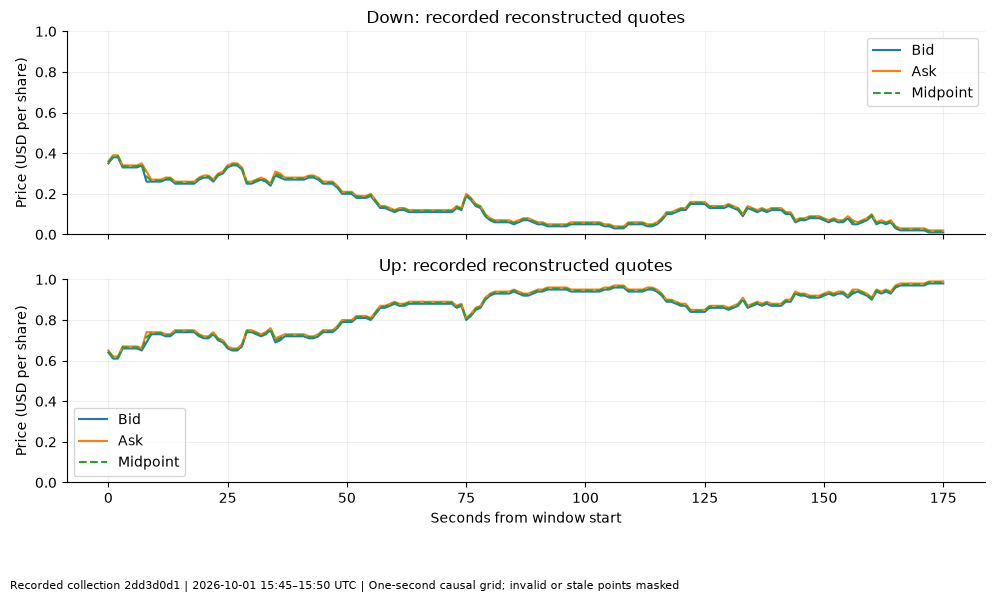

In [3]:
study = BookStudy(sample)
grid = study.grid()
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, (label, frame) in zip(axes, grid.groupby("label")):
    x = (frame.time - pd.Timestamp(sample.start, tz="UTC")).dt.total_seconds()
    ax.plot(x, frame.bid, label="Bid")
    ax.plot(x, frame.ask, label="Ask")
    ax.plot(x, frame.mid, linestyle="--", label="Midpoint")
    ax.set(title=f"{label}: recorded reconstructed quotes", ylabel="Price (USD per share)")
    ax.set_ylim(0, 1)
    ax.legend()
axes[-1].set_xlabel("Seconds from window start")
finish_plot(fig, sample, "One-second causal grid; invalid or stale points masked")

## 3. Complementary payouts do not imply free trading

For an illustrative qualified two-outcome $1 contract, one Up plus one Down pays
$1 in total. Buying both **asks** costs the ask sum. The midpoint sum can be near
$1 while the ask sum is higher. Also inspect displayed quantities and the different
arrival ages: two observed quotes are not an atomic executable transaction.

,ask_sum,bid_sum,mid_sum
count,176.000000,176.000000,176.0
mean,1.010398,0.989602,1.0
std,0.003271,0.003271,0.0
min,1.010000,0.950000,1.0
25%,1.010000,0.990000,1.0
50%,1.010000,0.990000,1.0
75%,1.010000,0.990000,1.0
max,1.050000,0.990000,1.0


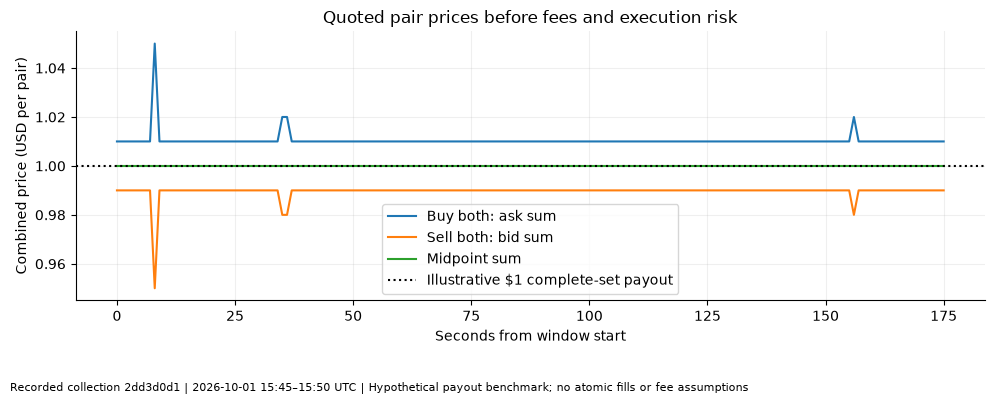

In [4]:
pair = paired_quotes(grid)
display(pair[["ask_sum", "bid_sum", "mid_sum"]].describe())
fig, ax = plt.subplots()
x = (pair.index - pd.Timestamp(sample.start, tz="UTC")).total_seconds()
for column, label in [
    ("ask_sum", "Buy both: ask sum"),
    ("bid_sum", "Sell both: bid sum"),
    ("mid_sum", "Midpoint sum"),
]:
    ax.plot(x, pair[column], label=label)
ax.axhline(1, color="black", linestyle=":", label="Illustrative $1 complete-set payout")
ax.set(
    title="Quoted pair prices before fees and execution risk",
    xlabel="Seconds from window start",
    ylabel="Combined price (USD per pair)",
)
ax.legend()
finish_plot(fig, sample, "Hypothetical payout benchmark; no atomic fills or fee assumptions")

## 4. Dollars spent versus number of shares

**Toy example, not a trade from this dataset:** Up costs $0.70 and Down costs $0.30.
Spending $5 on each buys different quantities. The two settlement outcomes then
have different profit. Equal *shares* hedge the binary payout; equal *dollars* do
not. Equal shares at a combined $1 cost make zero before fees in this toy example.

In [5]:
from decimal import Decimal

up_price, down_price = Decimal("0.70"), Decimal("0.30")
up_shares, down_shares = Decimal(5) / up_price, Decimal(5) / down_price
display(
    pd.DataFrame(
        [
            {
                "illustrative_outcome": "Up",
                "payout_USD": up_shares,
                "profit_before_fees_USD": up_shares - 10,
            },
            {
                "illustrative_outcome": "Down",
                "payout_USD": down_shares,
                "profit_before_fees_USD": down_shares - 10,
            },
        ]
    )
)
print(
    "100 shares of each: cost =",
    100 * (up_price + down_price),
    "; payout in either outcome = 100; profit before fees = 0.",
)

,illustrative_outcome,payout_USD,profit_before_fees_USD
0,Up,7.142857142857142857142857143,-2.857142857142857142857142857
1,Down,16.66666666666666666666666667,6.66666666666666666666666667


100 shares of each: cost = 100.00 ; payout in either outcome = 100; profit before fees = 0.


## 5. When was an outcome actually available?

Expiry and a provider's terminal observation are different times. A close flag is
not itself a verified payout label. The observations below may contain repeated
or unresolved statuses. We show the original fields without inventing a winner.

In [6]:
resolution = sample.frame("resolution_observations")
if not resolution.empty:
    display(resolution[["received_at", "provider_status", "payouts", "payout_unit"]].tail(8))
    print(
        "Earliest resolution observation after/before expiry (seconds):",
        (resolution.received_at.min() - pd.Timestamp(sample.end, tz="UTC")).total_seconds(),
    )
else:
    display(Markdown("No resolution observations were recorded. Outcome remains unavailable."))
assessment = sample.quality.get("settlement", {})
display(
    pd.Series(
        {
            k: assessment.get(k, "NOT_REPORTED")
            for k in ["status", "available_at", "payout_unit", "reason"]
        },
        name="Retrospective assessment",
    )
)

,received_at,provider_status,payouts,payout_unit
22,2026-10-01 16:06:04.185369300+00:00,resolved,"[1000000.000000000000000000000000000000, 0E-30]",UNKNOWN
23,2026-10-01 16:07:16.038146700+00:00,resolved,"[1000000.000000000000000000000000000000, 0E-30]",UNKNOWN
24,2026-10-01 16:08:31.597833400+00:00,resolved,"[1000000.000000000000000000000000000000, 0E-30]",UNKNOWN
25,2026-10-01 16:09:32.895456600+00:00,resolved,"[1000000.000000000000000000000000000000, 0E-30]",UNKNOWN
26,2026-10-01 16:10:45.568692900+00:00,resolved,"[1000000.000000000000000000000000000000, 0E-30]",UNKNOWN
27,2026-10-01 16:12:02.394948500+00:00,resolved,"[1000000.000000000000000000000000000000, 0E-30]",UNKNOWN
28,2026-10-01 16:13:16.343677400+00:00,resolved,"[1000000.000000000000000000000000000000, 0E-30]",UNKNOWN
29,2026-10-03 07:25:16.492829700+00:00,resolved,"[1000000.000000000000000000000000000000, 0E-30]",UNKNOWN


Earliest resolution observation after/before expiry (seconds): 304.861854


status                                    UNSUPPORTED
available_at                      1791012316492829700
payout_unit                              NOT_REPORTED
reason          status_or_payout_contract_unqualified
Name: Retrospective assessment, dtype: object

## Exercise — explain a supposed pair opportunity

Choose a time when both quotes are eligible. If the ask sum were below $1, what
else would you need before claiming a locked profit?

**Suggested answer:** enough size on both legs, actual fills at those prices,
historical fees and rounding, qualified complete-set mechanics, and the costs and
timing of merge or redemption. A one-leg fill introduces directional inventory.
The plot alone cannot establish those conditions.

**Research use:** time to expiry and leg identity are important explanatory
variables. **What remains unknown:** qualified settlement/payout semantics and
actual atomic execution. These lessons do not promote unsupported labels to truth.

Next: [04 — BTC statistics](04_btc_short_horizon_statistics.ipynb).